## 1. Project Overview and Objective

Compare three classifiers of 2015 forest persistence, conversion to agriculture and conversion to built-up land. Parcel IDs are the reporting regions. Evaluate on unseen parcels from 2015–2025, then rank all original forest parcels using predictions made without their own outcome. One decade of observations supports retrospective screening.

Run beside `land_use_change.csv` with the package versions recorded in the metadata. Running all cells generates the model, metadata, report, ranking and figures.

## 2. Dataset Loading and Inspection

Load the sole source file, record its fingerprint and inspect the actual columns and summary statistics.

In [1]:
from pathlib import Path
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import json
import joblib
from IPython.display import display, Markdown

SEED = 42
path = Path("land_use_change.csv")
source_hash = hashlib.sha256(path.read_bytes()).hexdigest()
artifacts = Path("forest_conversion_results")
plots = artifacts / "plots"
plots.mkdir(parents=True, exist_ok=True)
def save_plot(name):
    plt.gcf().savefig(plots / f"{name}.png", dpi=180, bbox_inches="tight")

df = pd.read_csv(path, dtype={"parcel_id": "string"})
base = ["dist_to_city_km", "dist_to_road_km", "slope_deg", "rainfall_mm",
        "soil_quality_idx", "ndvi_2015"]
status = "protected_area"
required = base + [status, "parcel_id", "land_use_2015", "land_use_2025",
                   "population_growth_pct", "changed"]
if missing := sorted(set(required) - set(df)):
    raise ValueError(f"Missing source columns: {missing}")
if df.parcel_id.isna().any() or df.parcel_id.duplicated().any():
    raise ValueError("Expected one nonmissing identifier per parcel.")
print("Source dimensions:", df.shape)
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))
display(df.describe(include="all").T)
print("Environment:", {p: metadata.version(p) for p in
                       ["pandas", "numpy", "scikit-learn", "xgboost", "shap", "matplotlib"]})
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 105})
colors = ["#246857", "#ba731c", "#5269aa"]

Source dimensions: (1000, 12)


,dtype,missing
parcel_id,string,0
land_use_2015,str,0
dist_to_city_km,float64,0
dist_to_road_km,float64,0
population_growth_pct,float64,0
slope_deg,float64,0
rainfall_mm,float64,0
soil_quality_idx,float64,0
protected_area,int64,0
ndvi_2015,float64,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
parcel_id,1000,1000,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
land_use_2015,1000,6,Cropland,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dist_to_city_km,1000.0,NaN,NaN,NaN,15.3232,10.728561,0.4,7.3,13.0,21.0,73.2
dist_to_road_km,1000.0,NaN,NaN,NaN,4.98329,3.788,0.05,2.3175,4.09,6.62,37.53
population_growth_pct,1000.0,NaN,NaN,NaN,1.48802,0.997019,-1.46,0.83,1.5,2.1625,5.0
slope_deg,1000.0,NaN,NaN,NaN,10.1317,7.343929,0.2,4.8,8.2,13.5,45.0
rainfall_mm,1000.0,NaN,NaN,NaN,1290.186,355.902096,300.0,1047.5,1272.0,1540.5,2292.0
soil_quality_idx,1000.0,NaN,NaN,NaN,0.51287,0.290893,0.0,0.25,0.52,0.77,1.0
protected_area,1000.0,NaN,NaN,NaN,0.161,0.367715,0.0,0.0,0.0,0.0,1.0
ndvi_2015,1000.0,NaN,NaN,NaN,0.627101,0.170897,0.114,0.512,0.644,0.75325,0.997


Environment: {'pandas': '3.1.0', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'xgboost': '3.4.1', 'shap': '0.54.1', 'matplotlib': '3.11.2'}


## 3. Data Quality Analysis

Count missing values and check parcel identifiers before matching outcomes or assigning folds. The shape check identifies changes to the hackathon source.

In [2]:
quality = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()})
quality.to_csv(artifacts / "data_quality.csv")
df.describe(include="all").T.to_csv(artifacts / "source_summary.csv")
assert df.shape == (1000, 12), "Review a changed source before comparing old results."

display(quality)

,dtype,missing
parcel_id,string,0
land_use_2015,str,0
dist_to_city_km,float64,0
dist_to_road_km,float64,0
population_growth_pct,float64,0
slope_deg,float64,0
rainfall_mm,float64,0
soil_quality_idx,float64,0
protected_area,int64,0
ndvi_2015,float64,0


## 4. Column Identification and Assumptions

The key is `parcel_id`. The year comes from `land_use_2015` and `land_use_2025`. The former selects the forest population and the latter supplies the observed destination. Only `ndvi_2015` explicitly dates a predictor. Assume road and city distances, rainfall and protected status describe baseline conditions, and that slope and soil quality are sufficiently stable. Unknown measurement dates could affect the results.

Population growth has an unknown measurement window. It is descriptive only. The model excludes IDs, both land-use columns, the target and the outcome flag `changed`. Road proximity is a single measurement. Infrastructure change cannot be measured here.

## 5. Land-Cover Transition Analysis

Count each observed origin and destination pair across all parcels. Cell annotations preserve counts for rare transitions.

land_use_2025,barren,built-up,cropland,forest,grassland,wetland,All
land_use_2015,,,,,,,
barren,66,22,5,0,3,0,96
built-up,0,86,2,0,0,0,88
cropland,0,37,257,3,3,0,300
forest,2,16,29,230,8,0,285
grassland,5,16,29,4,114,3,171
wetland,1,11,3,1,2,42,60
All,74,188,325,238,130,45,1000


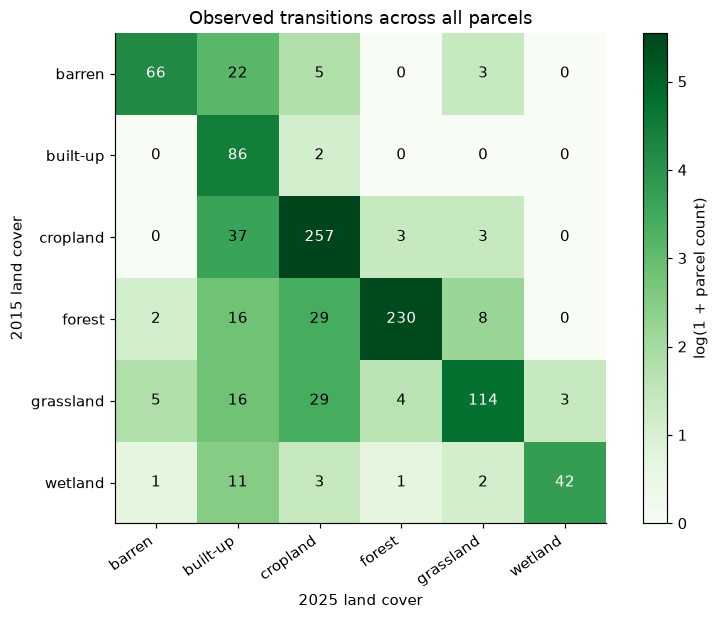

In [3]:
# Normalize spelling and whitespace without assigning unknown categories to a class.
def clean_cover(column):
    return df[column].astype("string").str.strip().str.lower().replace("", pd.NA)

start, end = clean_cover("land_use_2015"), clean_cover("land_use_2025")
display(pd.crosstab(start.fillna("missing"), end.fillna("missing"), margins=True))

transitions = pd.crosstab(start, end)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(np.log1p(transitions), cmap="Greens")
ax.set_xticks(range(len(transitions.columns)), transitions.columns, rotation=35, ha="right")
ax.set_yticks(range(len(transitions)), transitions.index)
for i, j in np.ndindex(transitions.shape):
    n = transitions.iloc[i,j]
    ax.text(j, i, str(n), ha="center", va="center", color="white" if n > 40 else "black")
ax.set(xlabel="2025 land cover", ylabel="2015 land cover", title="Observed transitions across all parcels")
fig.colorbar(im, ax=ax, label="log(1 + parcel count)")
fig.tight_layout()
save_plot("11_transition_matrix")
plt.show()

## 6. Forest Parcel Selection

Keep every parcel recorded as forest in 2015. This set defines the population for the ranked export.

In [4]:
forest = df.loc[start.eq("forest").fillna(False)].copy()
destination = end.loc[forest.index].fillna("missing")

print(len(forest), 'original forest parcels')

285 original forest parcels


## 7. Target Engineering

Map forest, cropland and built-up to three labels. Grassland and barren destinations have no training target. Built-up combines residential and industrial development.

In [5]:
classes = ["no_change", "to_agricultural", "to_built_up"]
forest["target"] = destination.map(dict(zip(["forest", "cropland", "built-up"], classes)))
eligible = forest.target.notna()
y = forest.loc[eligible, "target"].map(dict(zip(classes, range(3)))).astype(int)
codes = np.arange(3)
observed = destination.value_counts()
print("Forest parcels:", len(forest), "| Eligible:", len(y))
display(observed.rename("observed destinations").to_frame())
display(destination[~eligible].value_counts().rename("excluded destinations").to_frame())

assert observed.to_dict() == {"forest": 230, "cropland": 29, "built-up": 16, "grassland": 8, "barren": 2}
assert len(forest) == 285 and len(y) == 275
observed.rename("parcels").to_csv(artifacts / "observed_forest_transitions.csv")
pd.crosstab(start, end).to_csv(artifacts / "all_land_cover_transitions.csv")

Forest parcels: 285 | Eligible: 275


,observed destinations
land_use_2025,
forest,230
cropland,29
built-up,16
grassland,8
barren,2


,excluded destinations
land_use_2025,
grassland,8
barren,2


## 8. Exploratory Data Analysis

Compare land cover across the full dataset and inspect the labelled classes. The forest destination chart includes out-of-scope transitions.

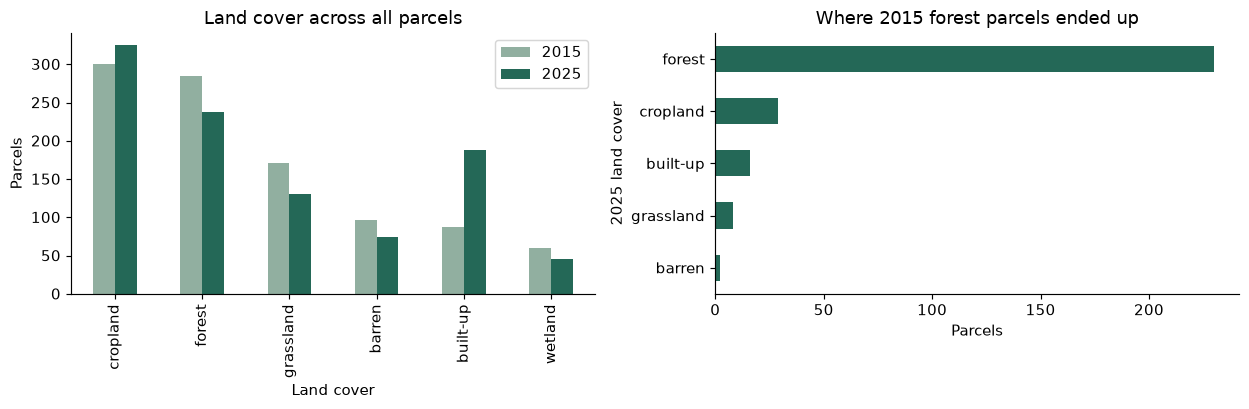

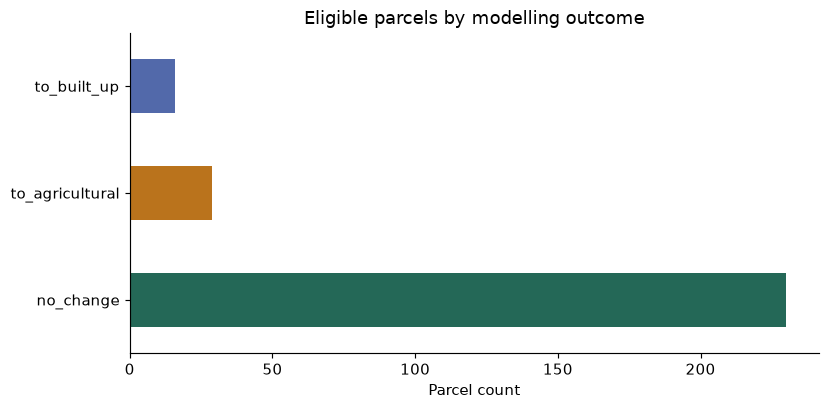

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
pd.concat([start.value_counts(), end.value_counts()], axis=1,
          keys=["2015", "2025"]).fillna(0).plot.bar(ax=axes[0], color=["#91afa0", colors[0]])
axes[0].set(title="Land cover across all parcels", ylabel="Parcels", xlabel="Land cover")
observed.sort_values().plot.barh(ax=axes[1], color=colors[0])
axes[1].set(title="Where 2015 forest parcels ended up", xlabel="Parcels", ylabel="2025 land cover")
fig.tight_layout()
save_plot("01_land_cover_and_forest_transitions")
plt.show()
y.value_counts().reindex(codes).set_axis(classes).plot.barh(color=colors)
plt.title("Eligible parcels by modelling outcome")
plt.xlabel("Parcel count")
plt.tight_layout()
save_plot("03_target_distribution")
plt.show()

## 9. Feature Engineering

Road accessibility increases as road distance falls. It measures proximity at one point in time. Infrastructure change would require repeated measurements. Soil suitability combines soil quality and a slope penalty capped through clipping. This is an unvalidated heuristic. Both proxies reuse baseline measurements, so related features may share importance.

The feature list excludes parcel ID, both land-use labels, the outcome flag and the undated growth rate. Correlations below describe eligible parcels and include the observed binary conversion indicator for context.

Predictors: ['dist_to_city_km', 'dist_to_road_km', 'slope_deg', 'rainfall_mm', 'soil_quality_idx', 'ndvi_2015', 'soil_suitability', 'road_accessibility', 'protected_area']


,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
no_change,230.0,1.420913,0.955644,-1.43,0.8425,1.490,2.0450,3.64
to_agricultural,29.0,1.727931,1.033453,0.12,1.1700,1.700,2.1400,4.39
to_built_up,16.0,1.652500,1.136236,-0.65,0.8075,1.595,2.6775,3.27


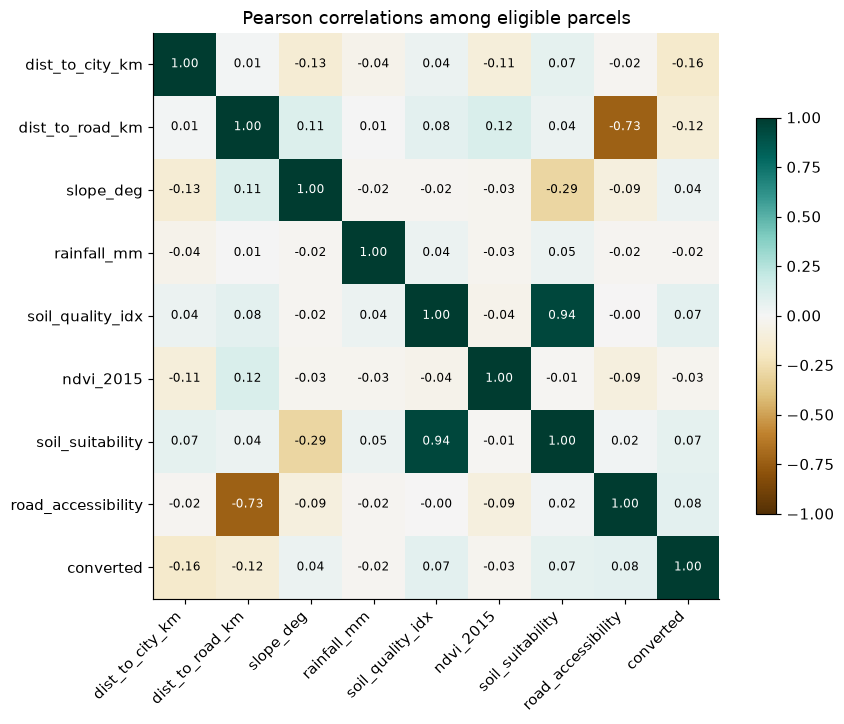

In [7]:
for col in base + ["population_growth_pct"]:
    forest[col] = pd.to_numeric(forest[col], errors="raise").replace([np.inf, -np.inf], np.nan)
if forest.dist_to_road_km.lt(0).any():
    raise ValueError("Road distance must be nonnegative.")
forest["soil_suitability"] = (forest.soil_quality_idx * (1 - forest.slope_deg / 45)).clip(0, 1)
forest["road_accessibility"] = 1 / (1 + forest.dist_to_road_km)
numeric = base + ["soil_suitability", "road_accessibility"]
features = numeric + [status]
X = forest[features].copy()
X[status] = X[status].astype("string").astype(object).where(X[status].notna(), np.nan)
print("Predictors:", features)
display(forest.groupby("target")["population_growth_pct"].describe())
# The heatmap uses numeric predictors; protected status is encoded later as categorical.
corr = forest.loc[y.index, numeric].assign(converted=y.ne(0).astype(int)).corr()
fig, ax = plt.subplots(figsize=(8.7, 7))
im = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i, j in np.ndindex(corr.shape):
    ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8,
            color="white" if abs(corr.iloc[i,j]) > .65 else "black")
ax.set_title("Pearson correlations among eligible parcels")
fig.colorbar(im, ax=ax, shrink=.7)
fig.tight_layout()
save_plot("02_feature_correlations")
plt.show()
assert not set(features) & {"parcel_id", "land_use_2015", "land_use_2025", "changed",
                            "target", "population_growth_pct"}
forest.groupby("target")["population_growth_pct"].describe().to_csv(artifacts / "undated_growth_descriptive.csv")

## 10. Data Preprocessing

Define the transformations here and fit them inside each training fold. Use the median and standard scaling for numbers, and most-frequent imputation and one-hot encoding for protected status. Unknown categories receive zero indicator values.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, roc_auc_score, roc_curve,
                             make_scorer)
from xgboost import XGBClassifier


from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score
transform = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler()), numeric),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent", keep_empty_features=True),
                          OneHotEncoder(handle_unknown="ignore", sparse_output=False)), [status])
], verbose_feature_names_out=False)

## 11. Train/Test Split

Split eligible parcels into 80% training and 20% test with seed 42. This holdout was previously inspected. The test set measures same-period performance. This run uses the requested forest depth constraint and a fixed candidate configuration for each model.

In [9]:
train, test = train_test_split(y.index.to_numpy(), test_size=.2, stratify=y, random_state=SEED)
split_counts = pd.DataFrame({"train": y.loc[train].value_counts(), "test": y.loc[test].value_counts()}).reindex(codes)
if split_counts.fillna(0).min().min() < 1:
    raise ValueError("Each outcome needs examples in both splits.")
display(split_counts.set_axis(classes))

assert len(train) == 220 and len(test) == 55 and not set(train) & set(test)

,train,test
no_change,184,46
to_agricultural,23,6
to_built_up,13,3


## 12. Cross-Validation

Use identical four-fold stratified splits for all candidates and the majority reference. Class balancing uses only labels passed to the fit. The reference always predicts the most common training class.

In [10]:
def fit_model(name, ids):
    pipe = Pipeline([("transform", clone(transform)), ("model", clone(models[name]))])
    params = {}
    if name == "XGBoost":
        params["model__sample_weight"] = compute_sample_weight("balanced", y.loc[ids])
    pipe.fit(X.loc[ids], y.loc[ids], **params)
    transformed = pipe.named_steps["transform"].transform(X.loc[ids])
    if transformed.ndim != 2 or not np.isfinite(transformed).all():
        raise ValueError("Preprocessing produced invalid values.")
    assert np.array_equal(pipe.classes_, codes), "Unexpected probability column ordering."
    return pipe

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
assert split_counts.train.min() >= 4
assert len(train) == 220 and len(test) == 55 and not set(train) & set(test)

models = {"Majority baseline": DummyClassifier(strategy="most_frequent")}
folds = list(cv.split(train, y.loc[train]))
fold_assignment = pd.Series(index=train, dtype="Int64")
for k, (a,b) in enumerate(folds, start=1):
    assert not set(train[a]) & set(train[b])
    fold_assignment.loc[train[b]] = k

def cv_scores(name):
    scores = []
    for a, b in folds:
        model = fit_model(name, train[a])
        pred = model.predict(X.loc[train[b]])
        scores.append(f1_score(y.loc[train[b]], pred, average="macro"))
    return scores

scores = {"Majority baseline": cv_scores("Majority baseline")}

## 13. Logistic Regression

Fit an L2-regularised baseline with class balancing. Each displayed value is macro-F1 on one validation fold.

In [11]:
models["Logistic Regression"] = LogisticRegression(C=.5, max_iter=2000, class_weight="balanced", random_state=SEED)
scores["Logistic Regression"] = cv_scores("Logistic Regression")
print(scores["Logistic Regression"])

[0.2404040404040404, 0.384030784030784, 0.3152043922591868, 0.5073906485671192]


## 14. Random Forest

Use 350 trees, at most six splits along a path, at least three samples per leaf and balanced class weights. Depth six is a fixed complexity limit for this small sample.

In [12]:
models["Random Forest"] = RandomForestClassifier(n_estimators=350, max_depth=6, min_samples_leaf=3,
    class_weight="balanced", n_jobs=2, random_state=SEED)
scores["Random Forest"] = cv_scores("Random Forest")
print(scores["Random Forest"])

[0.3853165804385317, 0.5132358063392546, 0.27675438596491225, 0.3181818181818182]


## 15. XGBoost

Fit shallow boosted trees with multiclass log loss and probability outputs. The fit function computes balanced sample weights from each fold's training labels.

In [13]:
models["XGBoost"] = XGBClassifier(n_estimators=140, max_depth=2, learning_rate=.04, objective="multi:softprob",
    eval_metric="mlogloss", n_jobs=2, random_state=SEED)
scores["XGBoost"] = cv_scores("XGBoost")
print(scores["XGBoost"])

[0.39109866168689694, 0.44451827242524916, 0.420615796519411, 0.3178219811131204]


## 16. Model Comparison and Selection

Select the main classifier with the highest mean training-fold macro-F1. The error bars show the sample standard deviation across four folds.

,1,2,3,4,mean,std
model,,,,,,
Majority baseline,0.304,0.304,0.304,0.304,0.304,0.000
Logistic Regression,0.240,0.384,0.315,0.507,0.362,0.113
Random Forest,0.385,0.513,0.277,0.318,0.373,0.103
XGBoost,0.391,0.445,0.421,0.318,0.394,0.055


Selected by mean training-CV macro-F1: XGBoost


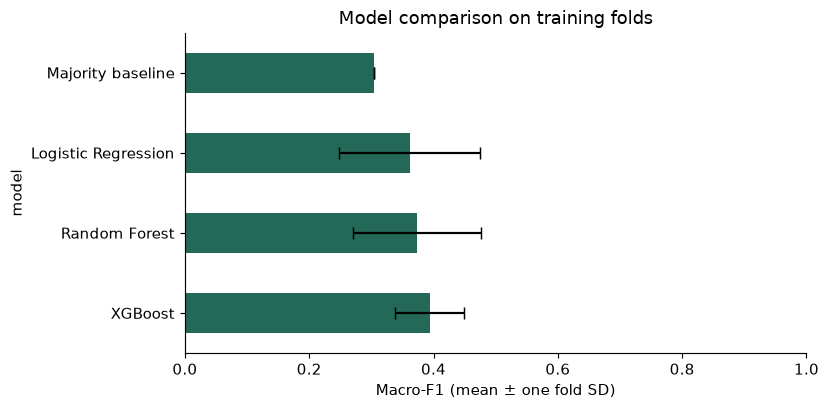

In [14]:
cv_table = pd.DataFrame(scores, index=[1,2,3,4]).T
cv_table.index.name = "model"
summary = cv_table.agg(["mean", "std"], axis=1).sort_values("mean", ascending=False)
best = summary.drop(index="Majority baseline").index[0]
display(cv_table.join(summary).round(3))
print("Selected by mean training-CV macro-F1:", best)
ax = summary["mean"].plot.barh(xerr=summary["std"], color=colors[0], capsize=4)
ax.set(xlim=(0, 1), xlabel="Macro-F1 (mean ± one fold SD)", title="Model comparison on training folds")
plt.tight_layout()
save_plot("04_training_cv_comparison")
plt.show()
cv_table.join(summary).to_csv(artifacts / "cross_validation_results.csv")
allocation = pd.DataFrame({"region": forest.loc[y.index, "parcel_id"], "target": forest.loc[y.index, "target"]})
allocation["partition"] = np.where(allocation.index.isin(train), "train", "test")
allocation["training_cv_fold"] = fold_assignment.reindex(allocation.index)
allocation.to_csv(artifacts / "evaluation_partitions.csv", index=False)

## 17. Final Test Evaluation

Refit each candidate and the majority reference on the 220 training parcels. Report every model on the same 55 test parcels. An unavailable one-vs-rest AUC is recorded as NaN.

Majority baseline
                 precision    recall  f1-score   support

      no_change       0.84      1.00      0.91        46
to_agricultural       0.00      0.00      0.00         6
    to_built_up       0.00      0.00      0.00         3

       accuracy                           0.84        55
      macro avg       0.28      0.33      0.30        55
   weighted avg       0.70      0.84      0.76        55



predicted,no_change,to_agricultural,to_built_up
observed,,,
no_change,46,0,0
to_agricultural,6,0,0
to_built_up,3,0,0


Logistic Regression
                 precision    recall  f1-score   support

      no_change       0.95      0.46      0.62        46
to_agricultural       0.15      0.50      0.23         6
    to_built_up       0.15      0.67      0.25         3

       accuracy                           0.47        55
      macro avg       0.42      0.54      0.37        55
   weighted avg       0.82      0.47      0.56        55



predicted,no_change,to_agricultural,to_built_up
observed,,,
no_change,21,16,9
to_agricultural,1,3,2
to_built_up,0,1,2


Random Forest
                 precision    recall  f1-score   support

      no_change       0.91      0.85      0.88        46
to_agricultural       0.38      0.50      0.43         6
    to_built_up       0.25      0.33      0.29         3

       accuracy                           0.78        55
      macro avg       0.51      0.56      0.53        55
   weighted avg       0.81      0.78      0.80        55



predicted,no_change,to_agricultural,to_built_up
observed,,,
no_change,39,4,3
to_agricultural,3,3,0
to_built_up,1,1,1


XGBoost
                 precision    recall  f1-score   support

      no_change       0.82      0.61      0.70        46
to_agricultural       0.08      0.17      0.11         6
    to_built_up       0.12      0.33      0.18         3

       accuracy                           0.55        55
      macro avg       0.34      0.37      0.33        55
   weighted avg       0.70      0.55      0.61        55



predicted,no_change,to_agricultural,to_built_up
observed,,,
no_change,28,11,7
to_agricultural,5,1,0
to_built_up,1,1,1


,CV_macro_F1_mean,CV_macro_F1_std,accuracy,balanced_accuracy,macro_F1,weighted_F1,macro_OVR_AUC,AUC_no_change,AUC_to_agricultural,AUC_to_built_up,...,f1-score_no_change,support_no_change,precision_to_agricultural,recall_to_agricultural,f1-score_to_agricultural,support_to_agricultural,precision_to_built_up,recall_to_built_up,f1-score_to_built_up,support_to_built_up
model,,,,,,,,,,,,,,,,,,,,,
XGBoost,0.394,0.055,0.545,0.370,0.329,0.607,0.765,0.662,0.762,0.872,...,0.700,46.0,0.077,0.167,0.105,6.0,0.125,0.333,0.182,3.0
Random Forest,0.373,0.103,0.782,0.560,0.530,0.795,0.790,0.696,0.810,0.865,...,0.876,46.0,0.375,0.500,0.429,6.0,0.250,0.333,0.286,3.0
Logistic Regression,0.362,0.113,0.473,0.541,0.366,0.555,0.719,0.727,0.643,0.788,...,0.618,46.0,0.150,0.500,0.231,6.0,0.154,0.667,0.250,3.0
Majority baseline,0.304,0.000,0.836,0.333,0.304,0.762,0.500,0.500,0.500,0.500,...,0.911,46.0,0.000,0.000,0.000,6.0,0.000,0.000,0.000,3.0


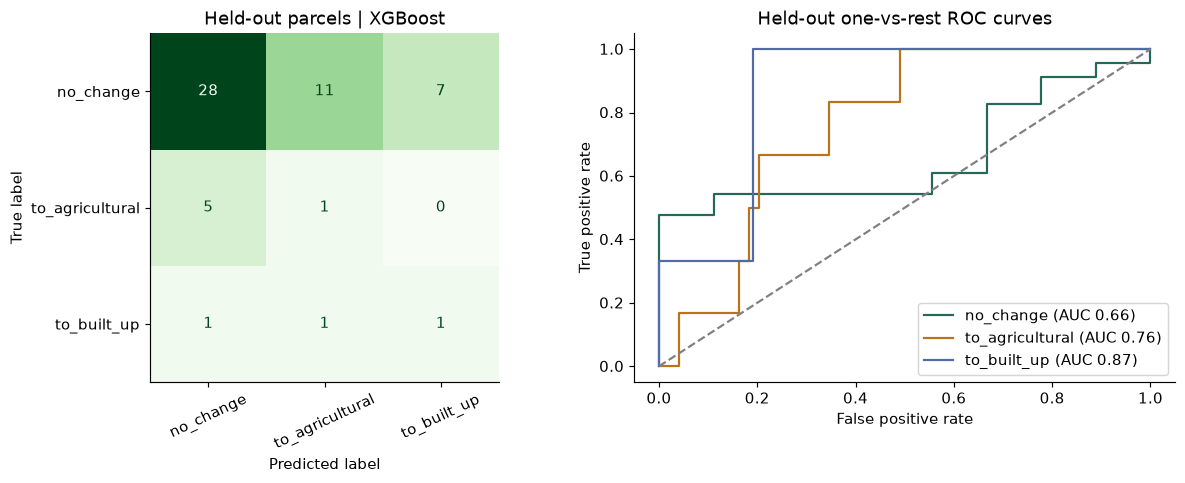

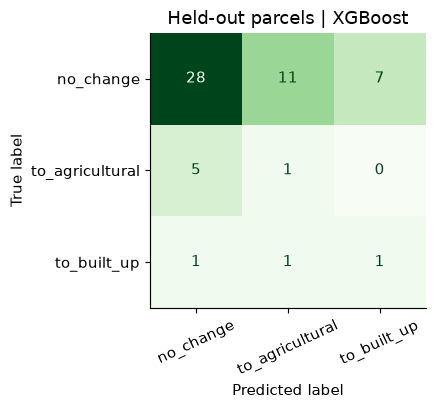

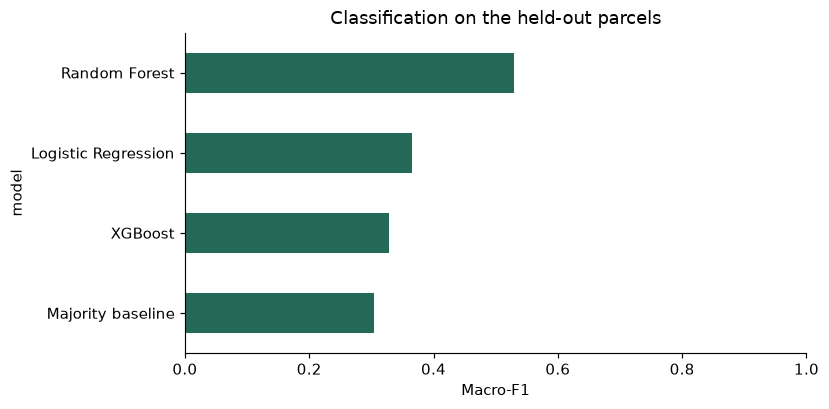

In [15]:
fitted, test_probs, results, reports = {}, {}, [], {}
for name in models:
    fitted[name] = fit_model(name, train)
    p = fitted[name].predict_proba(X.loc[test])
    test_probs[name] = p
    pred = p.argmax(axis=1)
    actual = y.loc[test]
    auc = [roc_auc_score(actual.eq(k), p[:, k]) if actual.eq(k).nunique() == 2 else np.nan for k in codes]
    results.append({"model": name, "accuracy": accuracy_score(actual, pred), "balanced_accuracy": balanced_accuracy_score(actual, pred),
                    "macro_F1": f1_score(actual, pred, average="macro"),
                    "weighted_F1": f1_score(actual, pred, average="weighted"),
                    "macro_OVR_AUC": np.mean(auc), **dict(zip(["AUC_" + c for c in classes], auc))})
    report = classification_report(actual, pred, labels=codes, target_names=classes,
                                    output_dict=True, zero_division=0)
    reports[name] = report
    for label in classes:
        results[-1].update({f"{measure}_{label}": report[label][measure]
                           for measure in ["precision", "recall", "f1-score", "support"]})
    print(name)
    print(classification_report(actual, pred, labels=codes, target_names=classes, zero_division=0))
    display(pd.DataFrame(confusion_matrix(actual, pred, labels=codes),
                         index=pd.Index(classes, name="observed"), columns=pd.Index(classes, name="predicted")))
metrics = summary.rename(columns={"mean":"CV_macro_F1_mean","std":"CV_macro_F1_std"}).join(pd.DataFrame(results).set_index("model"))
display(metrics.round(3))
winner, prob = fitted[best], test_probs[best]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
ConfusionMatrixDisplay.from_predictions(actual, prob.argmax(axis=1), display_labels=classes,
                                        cmap="Greens", colorbar=False, xticks_rotation=25, ax=axes[0])
axes[0].set_title(f"Held-out parcels | {best}")
for k, label in enumerate(classes):
    if actual.eq(k).nunique() == 2:
        fp, tp, _ = roc_curve(actual.eq(k), prob[:, k])
        axes[1].plot(fp, tp, color=colors[k], label=f"{label} (AUC {metrics.loc[best, 'AUC_'+label]:.2f})")
axes[1].plot([0,1], [0,1], "--", color="gray")
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="Held-out one-vs-rest ROC curves")
axes[1].legend()
fig.tight_layout()
save_plot("05_selected_confusion_matrix_and_roc")
plt.show()
metrics.to_csv(artifacts / "held_out_model_comparison.csv")
(artifacts / "classification_reports.json").write_text(json.dumps(reports, indent=2), encoding="utf-8")
pd.DataFrame({"region": forest.loc[test, "parcel_id"], "actual": actual.map(dict(enumerate(classes))),
              "predicted": pd.Series(prob.argmax(axis=1), index=test).map(dict(enumerate(classes))),
              **{f"probability_{label}": prob[:, k] for k, label in enumerate(classes)}}).to_csv(
                  artifacts / "held_out_predictions.csv", index=False)
# Save a separate selected-model confusion matrix for direct use in a presentation.
ConfusionMatrixDisplay.from_predictions(actual, prob.argmax(axis=1), display_labels=classes,
                                        cmap="Greens", xticks_rotation=25, colorbar=False)
plt.title(f"Held-out parcels | {best}")
plt.tight_layout()
save_plot("06_selected_confusion_matrix")
plt.show()

metrics.macro_F1.sort_values().plot.barh(color=colors[0], xlim=(0,1))
plt.xlabel("Macro-F1")
plt.title("Classification on the held-out parcels")
plt.tight_layout()
save_plot("12_test_macro_f1")
plt.show()

## 18. Feature Importance

After evaluation, fit the selected configuration on all 275 eligible parcels. Native importance describes this final artifact. Permutation importance measures how shuffling one predictor affects the evaluated 220-parcel fit on its held-out set. Related inputs can share importance.

C:\Users\LENOVO\AppData\Local\Temp\forest_lab_311b\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


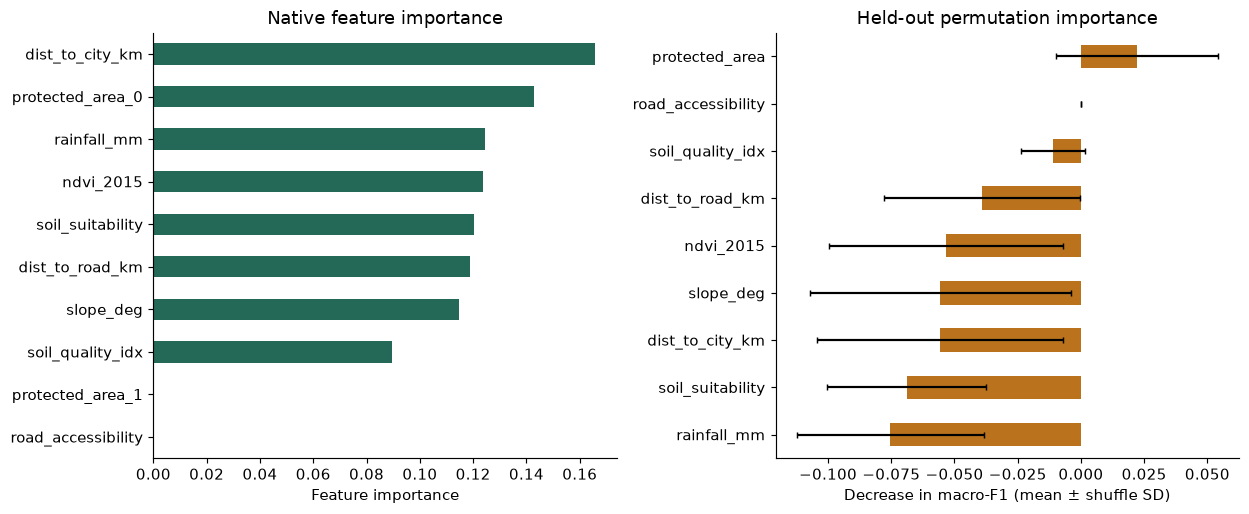

In [16]:
from sklearn.inspection import permutation_importance
import shap

final_model = fit_model(best, y.index)
prep = final_model.named_steps["transform"]
est = final_model.named_steps["model"]
names = prep.get_feature_names_out()
native = est.feature_importances_ if hasattr(est, "feature_importances_") else np.abs(est.coef_).mean(axis=0)
importance = permutation_importance(winner, X.loc[test], actual, n_repeats=25, random_state=SEED,
                                    scoring=make_scorer(f1_score, average="macro", zero_division=0))
perm = pd.Series(importance.importances_mean, index=features).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
pd.Series(native, index=names).sort_values().plot.barh(ax=axes[0], color=colors[0])
perm.plot.barh(ax=axes[1], color=colors[1],
               xerr=pd.Series(importance.importances_std, index=features).loc[perm.index], capsize=2)
axes[0].set(title="Native feature importance", xlabel="Mean absolute coefficient" if hasattr(est, "coef_") else "Feature importance")
axes[1].set(title="Held-out permutation importance", xlabel="Decrease in macro-F1 (mean ± shuffle SD)")
fig.tight_layout()
save_plot("07_native_and_permutation_importance")
plt.show()

## 19. SHAP Explainability

Explain the final pipeline on all eligible parcels against a reproducible sample of 48 baseline records. Positive contributions raise the combined conversion score above its background level. Negative contributions lower it. These associations describe the fitted model and cannot establish causes.

PermutationExplainer explainer:  97%|█████████▋| 266/275 [00:00<?, ?it/s]

PermutationExplainer explainer:  99%|█████████▊| 271/275 [00:10<00:00, 36.94it/s]

PermutationExplainer explainer: 100%|██████████| 275/275 [00:10<00:00, 29.47it/s]

PermutationExplainer explainer: 276it [00:10,  1.04s/it]                         

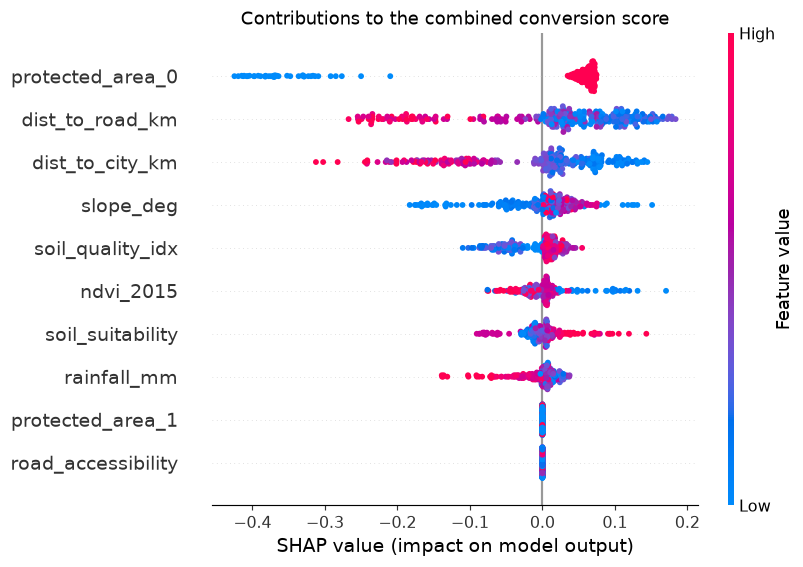

Largest mean absolute SHAP contributions:


,mean absolute contribution
protected_area_0,0.105195
dist_to_road_km,0.094224
dist_to_city_km,0.078659
slope_deg,0.039054
soil_quality_idx,0.028162


In [17]:
# Explain 1 minus the no-change score on the model's transformed feature scale.
no_change_col = list(est.classes_).index(classes.index("no_change"))
def conversion_score(matrix):
    return 1 - est.predict_proba(np.asarray(matrix))[:, no_change_col]

background = prep.transform(X.loc[y.index].sample(n=48, random_state=SEED))
matrix = prep.transform(X.loc[y.index])
explainer = shap.Explainer(conversion_score, background, algorithm="permutation",
                           feature_names=names.tolist(), seed=SEED)
explanation = explainer(matrix, max_evals=10 * (2 * len(names) + 1))
shap.plots.beeswarm(explanation, max_display=len(names), show=False)
plt.title("Contributions to the combined conversion score")
plt.tight_layout()
save_plot("08_shap_conversion_summary")
plt.show()
shap_rank = pd.Series(np.abs(explanation.values).mean(axis=0), index=names).sort_values(ascending=False)
print("Largest mean absolute SHAP contributions:")
display(shap_rank.head(5).to_frame("mean absolute contribution"))
pd.Series(native, index=names).rename("native_importance").to_csv(artifacts / "native_feature_importance.csv")
pd.DataFrame({"mean_decrease_macro_F1": importance.importances_mean,
              "shuffle_sd": importance.importances_std}, index=features).to_csv(
                  artifacts / "permutation_feature_importance.csv")
shap_rank.rename("mean_absolute_SHAP").to_csv(artifacts / "shap_importance.csv")
np.testing.assert_allclose(explanation.base_values + explanation.values.sum(axis=1),
                           conversion_score(matrix), atol=1e-5)

## 20. Out-of-Fold Risk Scoring

With model selection complete, use five new stratified folds over the full eligible set. Each parcel receives one prediction from a model trained on the other four folds. Out-of-scope parcels use the full-data fit. These historical scores are separate from the holdout accuracy estimate.

In [18]:
rank_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
p_all = pd.DataFrame(index=forest.index, columns=classes, dtype=float)
rank_fold = pd.Series(index=forest.index, dtype="Int64")
ids = y.index.to_numpy()
def named_probs(pipe, rows):
    arr = pipe.named_steps["transform"].transform(X.loc[rows])
    assert np.isfinite(arr).all()
    names = [classes[int(k)] for k in pipe.classes_]
    return pd.DataFrame(pipe.predict_proba(X.loc[rows]), index=rows, columns=names)[classes]

for fold, (a,b) in enumerate(rank_cv.split(ids, y), start=1):
    fit_ids, score_ids = ids[a], ids[b]
    assert set(fit_ids).isdisjoint(score_ids) and rank_fold.loc[score_ids].isna().all()
    fold_model = fit_model(best, fit_ids)
    p_all.loc[score_ids] = named_probs(fold_model, score_ids)
    rank_fold.loc[score_ids] = fold
outside = forest.index[~eligible]
assert len(outside) == 10 and set(outside).isdisjoint(ids)
assert rank_fold.loc[ids].value_counts().sort_index().tolist() == [55]*5
p_all.loc[outside] = named_probs(final_model, outside)
assert np.isfinite(p_all).all().all() and ((p_all >= 0) & (p_all <= 1)).all().all()
np.testing.assert_allclose(p_all.sum(axis=1), 1, atol=1e-6)
display(rank_fold.value_counts().sort_index().rename("eligible parcels scored"))

1    55
2    55
3    55
4    55
5    55
Name: eligible parcels scored, dtype: Int64

## 21. Regional Risk Ranking

For each 2015 forest parcel, compare both conversion destinations and separately identify the most likely overall outcome. Low is below 0.33, Medium is 0.33 to below 0.66 and High is at least 0.66. These fixed thresholds screen uncalibrated model scores. The ten excluded destinations have scores under the three-class model only.

,region,baseline_year,target_year,observed_2025_land_cover,observed_transition,scope_status,prediction_method,risk_score,probability_no_change,probability_agricultural,probability_built_up,most_likely_conversion_type,most_likely_overall_outcome,risk_level
311,312,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.941460,0.058540,0.734116,0.207344,to_agricultural,to_agricultural,High
133,134,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.918067,0.081933,0.688495,0.229573,to_agricultural,to_agricultural,High
110,111,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.894160,0.105840,0.065209,0.828951,to_built_up,to_built_up,High
437,438,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.888020,0.111980,0.056511,0.831509,to_built_up,to_built_up,High
343,344,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.885415,0.114585,0.172502,0.712914,to_built_up,to_built_up,High
694,695,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.884324,0.115676,0.866476,0.017848,to_agricultural,to_agricultural,High
448,449,2015,2025,Built-up,Forest -> Built-up,in_scope,five_fold_out_of_fold,0.883128,0.116872,0.156932,0.726196,to_built_up,to_built_up,High
126,127,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.865712,0.134288,0.113088,0.752624,to_built_up,to_built_up,High
188,189,2015,2025,Forest,Forest -> Forest,in_scope,five_fold_out_of_fold,0.861606,0.138394,0.196400,0.665206,to_built_up,to_built_up,High
930,931,2015,2025,Cropland,Forest -> Cropland,in_scope,five_fold_out_of_fold,0.860628,0.139372,0.202342,0.658286,to_built_up,to_built_up,High


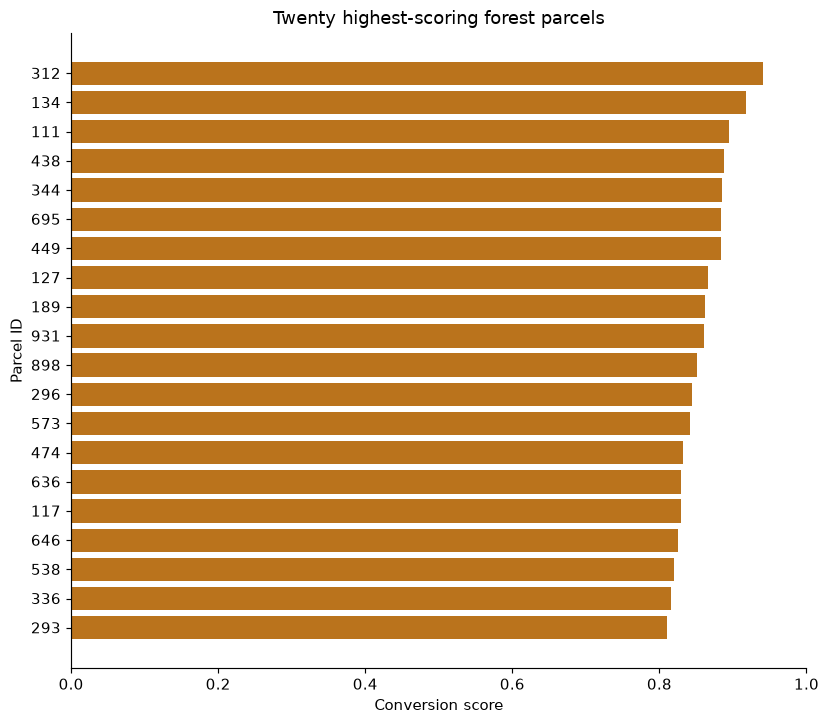

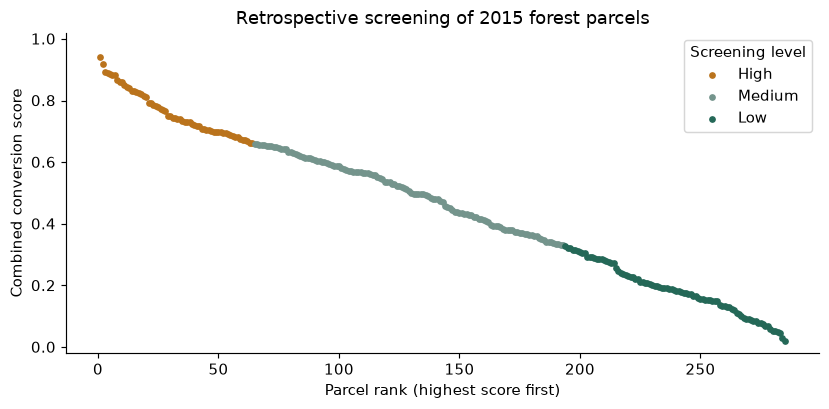

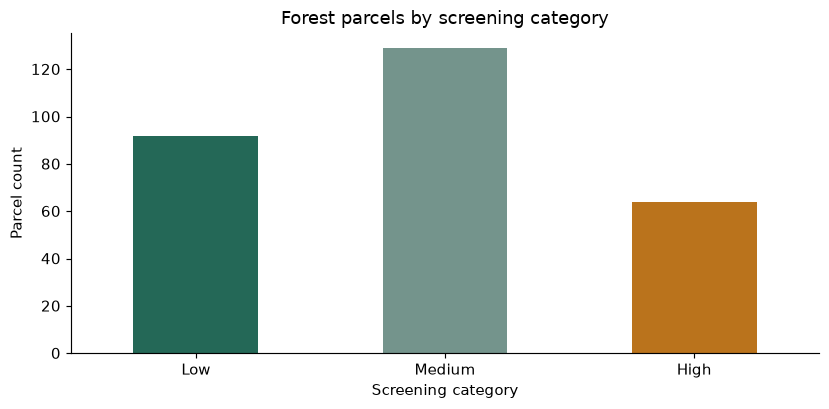

In [19]:
risk = pd.DataFrame({"region": forest.parcel_id, "baseline_year": 2015, "target_year": 2025,
    "observed_2025_land_cover": forest.land_use_2025,
    "observed_transition": forest.land_use_2015 + " -> " + forest.land_use_2025,
    "scope_status": np.where(eligible, "in_scope", "outside_scope"),
    "prediction_method": np.where(eligible, "five_fold_out_of_fold", "full_275_model"),
    "risk_score": 1 - p_all.no_change, "probability_no_change": p_all.no_change,
    "probability_agricultural": p_all.to_agricultural, "probability_built_up": p_all.to_built_up,
    "most_likely_conversion_type": p_all[classes[1:]].idxmax(axis=1),
    "most_likely_overall_outcome": p_all.idxmax(axis=1)})
risk["risk_level"] = pd.cut(risk.risk_score, [-np.inf, .33, .66, np.inf], labels=["Low","Medium","High"], right=False)
risk = risk.sort_values(["risk_score","region"], ascending=[False,True])
display(risk.head(10))
top = risk.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8,7))
ax.barh(top.region.tolist(), top.risk_score, color=colors[1])
ax.set(xlim=(0,1), xlabel="Conversion score", ylabel="Parcel ID", title="Twenty highest-scoring forest parcels")
fig.tight_layout()
save_plot("13_top_20_parcels")
plt.show()
fig, ax = plt.subplots()
for level, color in zip(["High", "Medium", "Low"], [colors[1], "#74948c", colors[0]]):
    mask = risk.risk_level.eq(level)
    ax.scatter(np.arange(1, len(risk)+1)[mask], risk.loc[mask, "risk_score"], s=13, label=level, color=color)
ax.set(xlabel="Parcel rank (highest score first)", ylabel="Combined conversion score",
       ylim=(-.02, 1.02), title="Retrospective screening of 2015 forest parcels")
ax.legend(title="Screening level")
plt.tight_layout()
save_plot("09_ranked_parcel_risk")
plt.show()
fig, ax = plt.subplots()
risk.risk_level.value_counts().reindex(["Low", "Medium", "High"], fill_value=0).plot.bar(
    ax=ax, color=[colors[0], "#74948c", colors[1]], rot=0)
ax.set(title="Forest parcels by screening category", xlabel="Screening category", ylabel="Parcel count")
plt.tight_layout()
save_plot("10_screening_categories")
plt.show()

## 22. Export Model and CSV

Save the fitted 275-parcel pipeline directly with joblib. It accepts a pandas DataFrame with the nine documented features, including the two deterministic proxies and string-valued protected status. Reload it and verify its probabilities against the in-memory fit. Verify the ranked CSV independently after reading it back.

In [20]:
from datetime import datetime, timezone
import shutil
execution = datetime.now(timezone.utc).isoformat()
versions = {p: metadata.version(p) for p in ["numpy","pandas","scikit-learn","xgboost","matplotlib","shap","joblib"]}
manifest = {"model_name": best, "model_parameters": {k:v for k,v in final_model.named_steps["model"].get_params().items()
                                                     if not isinstance(v,float) or np.isfinite(v)},
    "execution_date_utc": execution, "seed": SEED, "source_sha256": source_hash, "versions": versions,
    "feature_order": features, "numeric_features": numeric, "categorical_features": {status:"string, e.g. '0' or '1', or np.nan"},
    "feature_recipes": {"soil_suitability":"clip(soil_quality_idx * (1 - slope_deg/45), 0, 1)",
                        "road_accessibility":"1 / (1 + dist_to_road_km)"},
    "target_class_labels": {str(int(k)):classes[int(k)] for k in final_model.classes_},
    "rows": {"source":len(df),"forest":len(forest),"eligible_full_fit":len(y),"outside_scope":len(outside),
             "evaluation_train":len(train),"evaluation_test":len(test)},
    "risk_thresholds":{"medium_min":.33,"high_min":.66},
    "assumptions":["Undated distances, rainfall and protection describe baseline conditions; soil and slope are sufficiently static.",
                   "Population growth timing is unknown and this field is excluded."],
    "limitations":["One observed decade; temporal and spatial transfer untested.","Built-up has 16 examples and combines development types.",
                   "Class-weighted scores are uncalibrated. The target excludes grassland and barren destinations."],
    "artifact_fit":"All 275 eligible parcels. Only the ten outside-scope ranking rows use this model.",
    "ranking_fit":"Five-fold out-of-fold predictions for the 275 eligible parcels."}
model_path = Path("forest_conversion_model.joblib")
joblib.dump(final_model, model_path, compress=3)
metadata_path = Path("forest_conversion_model_metadata.json")
metadata_path.write_text(json.dumps(manifest, indent=2, allow_nan=False), encoding="utf-8")
loaded = joblib.load(model_path)
np.testing.assert_allclose(loaded.predict_proba(X[features]), final_model.predict_proba(X[features]))
np.testing.assert_allclose(named_probs(loaded,outside), p_all.loc[outside])
risk_path = Path("forest_conversion_risk.csv")
risk.to_csv(risk_path, index=False)
saved = pd.read_csv(risk_path, dtype={"region":"string"})
assert len(saved) == saved.region.nunique() == 285 and set(saved.region) == set(forest.parcel_id)
assert saved.risk_score.is_monotonic_decreasing
probs = saved[["probability_no_change","probability_agricultural","probability_built_up"]]
assert np.isfinite(probs).all().all() and ((probs >= 0) & (probs <= 1)).all().all()
np.testing.assert_allclose(probs.sum(axis=1), 1, atol=1e-6)
np.testing.assert_allclose(saved.risk_score, 1 - saved.probability_no_change, atol=1e-7)
np.testing.assert_allclose(saved.risk_score, saved.probability_agricultural + saved.probability_built_up, atol=1e-6)
assert set(saved.loc[saved.scope_status.eq("outside_scope"), "region"]) == set(forest.loc[outside,"parcel_id"])
assert hashlib.sha256(path.read_bytes()).hexdigest() == source_hash
audit = risk.assign(ranking_fold=rank_fold.reindex(risk.index))
audit.to_csv(artifacts / "risk_scope_and_provenance.csv", index=False)
risk.head(10).to_csv(artifacts / "top_high_risk_parcels.csv", index=False)
shutil.copyfile(model_path, artifacts / model_path.name)
shutil.copyfile(metadata_path, artifacts / "model_manifest.json")
checks = {"verified_at":execution, "rows":len(saved), "unique_ids":saved.region.nunique(),
          "outside_scope":len(outside), "source_hash_verified":True, "model_reload_verified":True,
          "five_disjoint_scoring_folds_verified":True, "probability_checks_passed":True,
          "SHAP_additivity_verified":True, "exported_plot_count":len(list(plots.glob("*.png")))}
(artifacts / "verification.json").write_text(json.dumps(checks, indent=2), encoding="utf-8")
display(checks)

{'verified_at': '2026-11-03T06:49:31.411605+00:00',
 'rows': 285,
 'unique_ids': 285,
 'outside_scope': 10,
 'source_hash_verified': True,
 'model_reload_verified': True,
 'five_disjoint_scoring_folds_verified': True,
 'probability_checks_passed': True,
 'SHAP_additivity_verified': True,
 'exported_plot_count': 13}

## 23. Final Results and Limitations

The report below uses the measured results from this run. The majority reference provides context for accuracy, and per-class recall shows how many rare outcomes the selected classifier recovered.

In [21]:
def md_table(frame):
    # Format a small table without an optional Markdown library.
    def cell(v):
        return f"{v:.3f}" if isinstance(v, (float,np.floating)) else str(v)
    rows = [frame.columns.tolist(), ["---"] * len(frame.columns), *frame.itertuples(index=False,name=None)]
    return "\n".join("| " + " | ".join(cell(v) for v in row) + " |" for row in rows)

comparison = metrics[["CV_macro_F1_mean","CV_macro_F1_std","accuracy","balanced_accuracy","macro_F1","weighted_F1","macro_OVR_AUC"]]
r = metrics.loc[best]
base_result = metrics.loc["Majority baseline"]
counts = risk.risk_level.value_counts()
per_class = pd.DataFrame({c:reports[best][c] for c in classes}).T
report = f"""# Forest conversion on unseen parcels, 2015–2025

The source contains {len(df)} parcels and {df.shape[1]} columns. Of 285 forest parcels, 230 stayed forest, 29 became cropland, 16 became built-up, eight became grassland and two became barren. The first three destinations form the 275 training labels. The ten remaining parcels appear in the risk file with their observed destination and outside-scope flag.

## Predictors and assumptions

The pipeline uses {', '.join(features)}. Soil suitability multiplies soil quality by (1 − slope/45) and clips it to [0,1]. Road accessibility equals 1/(1 + road distance in km). These proxies describe soil and access. The soil score is an unvalidated heuristic. Undated distance, protection and rainfall records are assumed available in 2015 and soil and slope sufficiently stable. Population growth has an unknown measurement period. It and the outcome flag were excluded.

## Model comparison

Four stratified folds within the 220-parcel training partition selected **{best}** by macro-F1. The remaining 55 parcels supplied the test results below. CV variation is the sample standard deviation across folds.

{md_table(comparison.reset_index())}

The selected model reached **{r.macro_F1:.3f} test macro-F1** versus {base_result.macro_F1:.3f} for always predicting forest persistence. Its accuracy was {r.accuracy:.1%} versus {base_result.accuracy:.1%} for the majority rule. The previous workflow already inspected this holdout. No test-driven tuning was performed. The requested forest depth cap was fixed before this run.

{md_table(per_class.rename_axis("outcome").reset_index())}

Built-up recall rests on {int(per_class.loc[classes[2],"support"])} test cases. One additional correct prediction changes it by {1/per_class.loc[classes[2],"support"]:.0%}.

## Explanation of the full model

{', '.join(shap_rank.head(3).index)} had the largest mean absolute SHAP contributions to the combined conversion score. Indicator suffixes on protected_area denote one-hot categories. Positive SHAP contributions increase a parcel's score relative to the training background. These associations cannot establish causation. The permutation chart measures held-out performance of the evaluation fit and may divide importance among correlated predictors.

## Retrospective parcel ranking

The five-fold ranking scores each eligible parcel while excluding it from fitting. The separately saved pipeline trained on all 275 eligible parcels scores the ten outside-scope parcels under the restricted outcome definition. Among 285 parcels, {counts['High']} are High (at least 0.66), {counts['Medium']} Medium (0.33 to below 0.66) and {counts['Low']} Low (below 0.33).

{md_table(risk.head(10)[["region","risk_score","most_likely_conversion_type","most_likely_overall_outcome","scope_status"]])}

## Limits and future improvements

The scores are uncalibrated screening indicators. The parcel split measures performance within one decade. Spatial and future-year performance are unknown. Built-up combines residential and industrial conversion, and these labels do not measure sustainability. With this CSV, repeated nested stratified splits could assess split sensitivity. Calibration would require separate validation, particularly for the rare outcomes.
"""
Path("forest_conversion_final_report.md").write_text(report, encoding="utf-8")
(artifacts / "project_report.md").write_text(report, encoding="utf-8")
display(Markdown(report))

# Forest conversion on unseen parcels, 2015–2025

The source contains 1000 parcels and 12 columns. Of 285 forest parcels, 230 stayed forest, 29 became cropland, 16 became built-up, eight became grassland and two became barren. The first three destinations form the 275 training labels. The ten remaining parcels appear in the risk file with their observed destination and outside-scope flag.

## Predictors and assumptions

The pipeline uses dist_to_city_km, dist_to_road_km, slope_deg, rainfall_mm, soil_quality_idx, ndvi_2015, soil_suitability, road_accessibility, protected_area. Soil suitability multiplies soil quality by (1 − slope/45) and clips it to [0,1]. Road accessibility equals 1/(1 + road distance in km). These proxies describe soil and access. The soil score is an unvalidated heuristic. Undated distance, protection and rainfall records are assumed available in 2015 and soil and slope sufficiently stable. Population growth has an unknown measurement period. It and the outcome flag were excluded.

## Model comparison

Four stratified folds within the 220-parcel training partition selected **XGBoost** by macro-F1. The remaining 55 parcels supplied the test results below. CV variation is the sample standard deviation across folds.

| model | CV_macro_F1_mean | CV_macro_F1_std | accuracy | balanced_accuracy | macro_F1 | weighted_F1 | macro_OVR_AUC |
| --- | --- | --- | --- | --- | --- | --- | --- |
| XGBoost | 0.394 | 0.055 | 0.545 | 0.370 | 0.329 | 0.607 | 0.765 |
| Random Forest | 0.373 | 0.103 | 0.782 | 0.560 | 0.530 | 0.795 | 0.790 |
| Logistic Regression | 0.362 | 0.113 | 0.473 | 0.541 | 0.366 | 0.555 | 0.719 |
| Majority baseline | 0.304 | 0.000 | 0.836 | 0.333 | 0.304 | 0.762 | 0.500 |

The selected model reached **0.329 test macro-F1** versus 0.304 for always predicting forest persistence. Its accuracy was 54.5% versus 83.6% for the majority rule. The previous workflow already inspected this holdout. No test-driven tuning was performed. The requested forest depth cap was fixed before this run.

| outcome | precision | recall | f1-score | support |
| --- | --- | --- | --- | --- |
| no_change | 0.824 | 0.609 | 0.700 | 46.000 |
| to_agricultural | 0.077 | 0.167 | 0.105 | 6.000 |
| to_built_up | 0.125 | 0.333 | 0.182 | 3.000 |

Built-up recall rests on 3 test cases. One additional correct prediction changes it by 33%.

## Explanation of the full model

protected_area_0, dist_to_road_km, dist_to_city_km had the largest mean absolute SHAP contributions to the combined conversion score. Indicator suffixes on protected_area denote one-hot categories. Positive SHAP contributions increase a parcel's score relative to the training background. These associations cannot establish causation. The permutation chart measures held-out performance of the evaluation fit and may divide importance among correlated predictors.

## Retrospective parcel ranking

The five-fold ranking scores each eligible parcel while excluding it from fitting. The separately saved pipeline trained on all 275 eligible parcels scores the ten outside-scope parcels under the restricted outcome definition. Among 285 parcels, 64 are High (at least 0.66), 129 Medium (0.33 to below 0.66) and 92 Low (below 0.33).

| region | risk_score | most_likely_conversion_type | most_likely_overall_outcome | scope_status |
| --- | --- | --- | --- | --- |
| 312 | 0.941 | to_agricultural | to_agricultural | in_scope |
| 134 | 0.918 | to_agricultural | to_agricultural | in_scope |
| 111 | 0.894 | to_built_up | to_built_up | in_scope |
| 438 | 0.888 | to_built_up | to_built_up | in_scope |
| 344 | 0.885 | to_built_up | to_built_up | in_scope |
| 695 | 0.884 | to_agricultural | to_agricultural | in_scope |
| 449 | 0.883 | to_built_up | to_built_up | in_scope |
| 127 | 0.866 | to_built_up | to_built_up | in_scope |
| 189 | 0.862 | to_built_up | to_built_up | in_scope |
| 931 | 0.861 | to_built_up | to_built_up | in_scope |

## Limits and future improvements

The scores are uncalibrated screening indicators. The parcel split measures performance within one decade. Spatial and future-year performance are unknown. Built-up combines residential and industrial conversion, and these labels do not measure sustainability. With this CSV, repeated nested stratified splits could assess split sensitivity. Calibration would require separate validation, particularly for the rare outcomes.
